In [1]:
"""
01_fundamentos.py — Fundamentos de Sistemas de Recomendación
=============================================================

Este módulo cubre los conceptos básicos de los sistemas de recomendación:
1. ¿Qué es un sistema de recomendación?
2. Tipos principales (filtrado colaborativo, basado en contenido, híbrido)
3. Análisis exploratorio del dataset de películas
4. Implementación de un Recomendador Simple por Popularidad
   - Fórmula de Rating Ponderado (Weighted Rating / IMDB)
   - Top-N global
   - Top-N filtrado por género
"""

'\n01_fundamentos.py — Fundamentos de Sistemas de Recomendación\n=============================================================\n\nEste módulo cubre los conceptos básicos de los sistemas de recomendación:\n1. ¿Qué es un sistema de recomendación?\n2. Tipos principales (filtrado colaborativo, basado en contenido, híbrido)\n3. Análisis exploratorio del dataset de películas\n4. Implementación de un Recomendador Simple por Popularidad\n   - Fórmula de Rating Ponderado (Weighted Rating / IMDB)\n   - Top-N global\n   - Top-N filtrado por género\n'

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import load_and_clean_data, weighted_rating

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
})

OUTPUT_DIR = "output"
def ensure_output_dir():
    import os
    os.makedirs(OUTPUT_DIR, exist_ok=True)
ensure_output_dir()

=============================================================================
PARTE 1: Teoría — ¿Qué es un Sistema de Recomendación?
=============================================================================

In [3]:
def print_teoria():
    """
    Imprime una explicación teórica de los sistemas de recomendación.
    """
    teoria = """
    ╔══════════════════════════════════════════════════════════════════════╗
    ║           FUNDAMENTOS DE SISTEMAS DE RECOMENDACIÓN                 ║
    ╠══════════════════════════════════════════════════════════════════════╣
    ║                                                                    ║
    ║  Un sistema de recomendación es un algoritmo que sugiere ítems     ║
    ║  relevantes a los usuarios basándose en diferentes señales.        ║
    ║                                                                    ║
    ║  ┌─────────────────────────────────────────────────────────────┐   ║
    ║  │  TIPOS PRINCIPALES:                                        │   ║
    ║  │                                                            │   ║
    ║  │  1. 📊 SIMPLE (Por Popularidad)                            │   ║
    ║  │     → Recomienda lo más popular/mejor valorado              │   ║
    ║  │     → No personalizado, igual para todos                   │   ║
    ║  │     → Ej: "Top 10 películas más vistas"                    │   ║
    ║  │                                                            │   ║
    ║  │  2. 🎯 BASADO EN CONTENIDO (Content-Based)                 │   ║
    ║  │     → Analiza las características del ítem                 │   ║
    ║  │     → Recomienda ítems similares a los que te gustaron     │   ║
    ║  │     → Ej: "Si te gustó Toy Story → te gustará Shrek"      │   ║
    ║  │                                                            │   ║
    ║  │  3. 👥 FILTRADO COLABORATIVO (Collaborative)               │   ║
    ║  │     → Usa las preferencias de usuarios similares           │   ║
    ║  │     → "Usuarios como tú también vieron..."                 │   ║
    ║  │     → Requiere datos de interacción usuario-ítem           │   ║
    ║  │                                                            │   ║
    ║  │  4. 🔀 HÍBRIDO                                             │   ║
    ║  │     → Combina contenido + colaborativo                     │   ║
    ║  │     → Máxima precisión, mayor complejidad                  │   ║
    ║  └─────────────────────────────────────────────────────────────┘   ║
    ║                                                                    ║
    ║  En este proyecto nos enfocamos en (1) y (2).                     ║
    ╚══════════════════════════════════════════════════════════════════════╝
    """
    print(teoria)

print_teoria()


    ╔══════════════════════════════════════════════════════════════════════╗
    ║           FUNDAMENTOS DE SISTEMAS DE RECOMENDACIÓN                 ║
    ╠══════════════════════════════════════════════════════════════════════╣
    ║                                                                    ║
    ║  Un sistema de recomendación es un algoritmo que sugiere ítems     ║
    ║  relevantes a los usuarios basándose en diferentes señales.        ║
    ║                                                                    ║
    ║  ┌─────────────────────────────────────────────────────────────┐   ║
    ║  │  TIPOS PRINCIPALES:                                        │   ║
    ║  │                                                            │   ║
    ║  │  1. 📊 SIMPLE (Por Popularidad)                            │   ║
    ║  │     → Recomienda lo más popular/mejor valorado              │   ║
    ║  │     → No personalizado, igual para todos                   │   ║
    ║  │     → Ej: "Top 1

=============================================================================
PARTE 2: Análisis Exploratorio de Datos (EDA)
=============================================================================

📂 Cargando movies_metadata.csv...


🔧 Parseando columnas JSON (genres, production_companies)...


✅ Dataset listo: 45433 películas cargadas

📊 ANÁLISIS EXPLORATORIO DE DATOS

📈 Estadísticas generales:
   Total de películas: 45,433
   Rango de años: 1874 - 2020
   Rating promedio: 5.62
   Mediana de votos: 10
   Películas con overview: 44,479


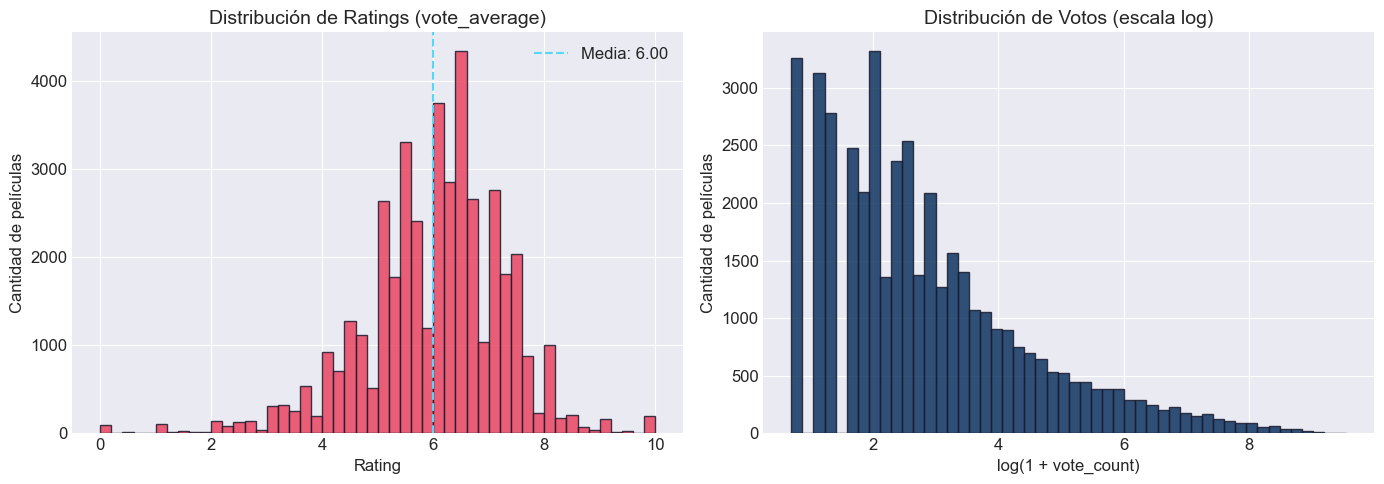

   💾 Guardado: output/01_distribucion_ratings_votos.png


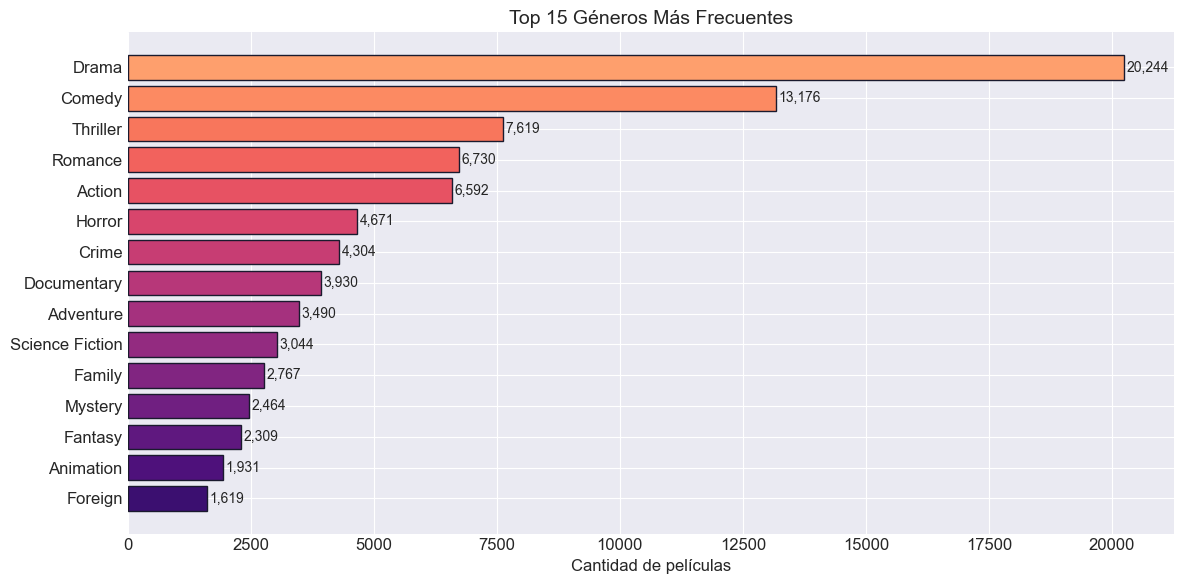

   💾 Guardado: output/01_top_generos.png


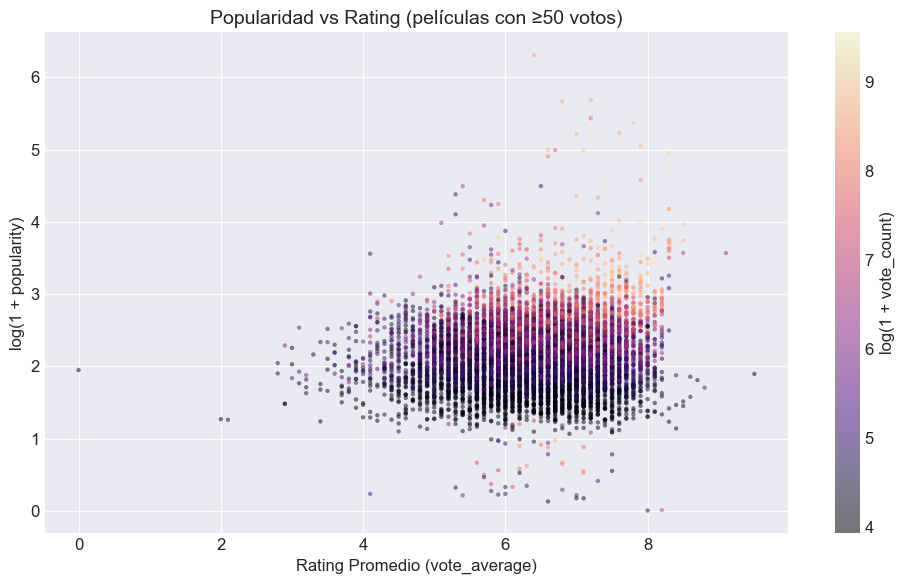

   💾 Guardado: output/01_popularidad_vs_rating.png


In [4]:
def analisis_exploratorio(df):
    """
    Realiza un análisis exploratorio del dataset de películas.
    Genera y guarda visualizaciones:
    - Distribución de ratings y votos
    - Top géneros más frecuentes
    - Popularidad vs rating
    """
    ensure_output_dir()
    print("\n" + "=" * 70)
    print("📊 ANÁLISIS EXPLORATORIO DE DATOS")
    print("=" * 70)

    print(f"\n📈 Estadísticas generales:")
    print(f"   Total de películas: {len(df):,}")
    print(f"   Rango de años: {df['year'].min():.0f} - {df['year'].max():.0f}")
    print(f"   Rating promedio: {df['vote_average'].mean():.2f}")
    print(f"   Mediana de votos: {df['vote_count'].median():.0f}")
    print(f"   Películas con overview: {(df['overview'] != '').sum():,}")

    # --- Gráfico 1 & 2: Distribución de ratings y votos ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    rated = df[df["vote_count"] > 0]
    axes[0].hist(rated["vote_average"], bins=50, color="#e94560", edgecolor="#1a1a2e", alpha=0.85)
    axes[0].set_title("Distribución de Ratings (vote_average)")
    axes[0].set_xlabel("Rating")
    axes[0].set_ylabel("Cantidad de películas")
    axes[0].axvline(rated["vote_average"].mean(), color="#53d8fb", linestyle="--",
                    label=f"Media: {rated['vote_average'].mean():.2f}")
    axes[0].legend()

    voted = df[df["vote_count"] > 0]
    axes[1].hist(np.log1p(voted["vote_count"]), bins=50, color="#0f3460", edgecolor="#1a1a2e", alpha=0.85)
    axes[1].set_title("Distribución de Votos (escala log)")
    axes[1].set_xlabel("log(1 + vote_count)")
    axes[1].set_ylabel("Cantidad de películas")

    plt.tight_layout()
    path_dist = f"{OUTPUT_DIR}/01_distribucion_ratings_votos.png"
    plt.savefig(path_dist, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"   💾 Guardado: {path_dist}")

    # --- Gráfico 3: Top 15 géneros más frecuentes ---
    all_genres = df["genres_list"].explode()
    genre_counts = all_genres.value_counts().head(15)

    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.barh(genre_counts.index[::-1], genre_counts.values[::-1],
                   color=plt.cm.magma(np.linspace(0.2, 0.8, 15)), edgecolor="#1a1a2e")
    ax.set_title("Top 15 Géneros Más Frecuentes")
    ax.set_xlabel("Cantidad de películas")

    for bar, count in zip(bars, genre_counts.values[::-1]):
        ax.text(bar.get_width() + 50, bar.get_y() + bar.get_height() / 2,
                f"{count:,}", va="center", fontsize=10)

    plt.tight_layout()
    path_genres = f"{OUTPUT_DIR}/01_top_generos.png"
    plt.savefig(path_genres, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"   💾 Guardado: {path_genres}")

    # --- Gráfico 4: Popularidad vs Rating ---
    popular = df[df["vote_count"] >= 50].copy()
    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(
        popular["vote_average"],
        np.log1p(popular["popularity"]),
        c=np.log1p(popular["vote_count"]),
        cmap="magma",
        alpha=0.5,
        s=10,
        edgecolors="none"
    )
    ax.set_title("Popularidad vs Rating (películas con ≥50 votos)")
    ax.set_xlabel("Rating Promedio (vote_average)")
    ax.set_ylabel("log(1 + popularity)")
    plt.colorbar(scatter, label="log(1 + vote_count)")

    plt.tight_layout()
    path_pop = f"{OUTPUT_DIR}/01_popularidad_vs_rating.png"
    plt.savefig(path_pop, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"   💾 Guardado: {path_pop}")

# Cargar datos y ejecutar análisis exploratorio
df = load_and_clean_data(include_keywords=False)
analisis_exploratorio(df)

=============================================================================
PARTE 3: Recomendador Simple por Popularidad (Fórmula IMDB)
=============================================================================

In [5]:
def simple_recommender(df, percentile=0.90, top_n=15):
    """
    Implementa un Recomendador Simple basado en popularidad usando
    la fórmula de Weighted Rating (WR) de IMDB:
        WR = (v / (v + m)) * R + (m / (v + m)) * C
    """
    print("\n" + "=" * 70)
    print("🏆 RECOMENDADOR SIMPLE (POR POPULARIDAD)")
    print("=" * 70)

    # Calcular C (rating promedio global)
    C = df["vote_average"].mean()
    print(f"\n   📊 Rating promedio global (C): {C:.4f}")

    # Calcular m (mínimo de votos, percentil 90 por defecto)
    m = df["vote_count"].quantile(percentile)
    print(f"   📊 Mínimo de votos requerido (m, percentil {percentile*100:.0f}%): {m:.0f}")

    # Filtrar películas que cumplen el mínimo de votos
    qualified = df[df["vote_count"] >= m].copy()
    print(f"   📊 Películas que califican: {len(qualified):,} de {len(df):,}")

    # Calcular el weighted rating para cada película calificada
    qualified["weighted_rating"] = qualified.apply(
        weighted_rating, axis=1, m=m, C=C
    )

    # Ordenar por weighted rating descendente
    qualified = qualified.sort_values("weighted_rating", ascending=False)

    # Mostrar Top-N
    top = qualified.head(top_n)
    print(f"\n   🎬 TOP {top_n} PELÍCULAS (Rating Ponderado):")
    print("   " + "─" * 66)

    for i, (_, row) in enumerate(top.iterrows(), 1):
        year_str = f" ({int(row['year'])})" if pd.notna(row['year']) else ""
        print(f"   {i:2d}. {row['title']}{year_str}")
        print(f"       WR: {row['weighted_rating']:.2f} │ "
              f"Rating: {row['vote_average']:.1f} │ "
              f"Votos: {row['vote_count']:,.0f} │ "
              f"Géneros: {row['genres_str']}")

    return qualified

qualified = simple_recommender(df, percentile=0.90, top_n=15)


🏆 RECOMENDADOR SIMPLE (POR POPULARIDAD)

   📊 Rating promedio global (C): 5.6180
   📊 Mínimo de votos requerido (m, percentil 90%): 160
   📊 Películas que califican: 4,551 de 45,433

   🎬 TOP 15 PELÍCULAS (Rating Ponderado):
   ──────────────────────────────────────────────────────────────────
    1. The Shawshank Redemption (1994)
       WR: 8.45 │ Rating: 8.5 │ Votos: 8,358 │ Géneros: Drama, Crime
    2. The Godfather (1972)
       WR: 8.43 │ Rating: 8.5 │ Votos: 6,024 │ Géneros: Drama, Crime
    3. Dilwale Dulhania Le Jayenge (1995)
       WR: 8.42 │ Rating: 9.1 │ Votos: 661 │ Géneros: Comedy, Drama, Romance
    4. The Dark Knight (2008)
       WR: 8.27 │ Rating: 8.3 │ Votos: 12,269 │ Géneros: Drama, Action, Crime, Thriller
    5. Fight Club (1999)
       WR: 8.26 │ Rating: 8.3 │ Votos: 9,678 │ Géneros: Drama
    6. Pulp Fiction (1994)
       WR: 8.25 │ Rating: 8.3 │ Votos: 8,670 │ Géneros: Thriller, Crime
    7. Schindler's List (1993)
       WR: 8.21 │ Rating: 8.3 │ Votos: 4,436 

In [6]:
def recommend_by_genre(df, genre, percentile=0.85, top_n=10):
    """
    Recomienda las mejores películas de un género específico
    usando el mismo sistema de Weighted Rating.
    """
    genre_df = df[df["genres_list"].apply(lambda x: genre in x)].copy()

    if genre_df.empty:
        print(f"   ⚠️  No se encontraron películas del género '{genre}'")
        return pd.DataFrame()

    C = genre_df["vote_average"].mean()
    m = genre_df["vote_count"].quantile(percentile)

    qualified_genre = genre_df[genre_df["vote_count"] >= m].copy()
    qualified_genre["weighted_rating"] = qualified_genre.apply(
        weighted_rating, axis=1, m=m, C=C
    )
    qualified_genre = qualified_genre.sort_values("weighted_rating", ascending=False)

    top = qualified_genre.head(top_n)
    print(f"\n   🎬 TOP {top_n} PELÍCULAS — Género: {genre}")
    print(f"   (C={C:.2f}, m={m:.0f}, {len(qualified_genre)} califican)")
    print("   " + "─" * 66)

    for i, (_, row) in enumerate(top.iterrows(), 1):
        year_str = f" ({int(row['year'])})" if pd.notna(row['year']) else ""
        print(f"   {i:2d}. {row['title']}{year_str}")
        print(f"       WR: {row['weighted_rating']:.2f} │ "
              f"Rating: {row['vote_average']:.1f} │ "
              f"Votos: {row['vote_count']:,.0f}")

    return qualified_genre

print("\n" + "=" * 70)
print("🎭 RECOMENDACIONES POR GÉNERO")
print("=" * 70)

for genre in ["Animation", "Science Fiction", "Drama"]:
    recommend_by_genre(df, genre, percentile=0.85, top_n=5)


🎭 RECOMENDACIONES POR GÉNERO

   🎬 TOP 5 PELÍCULAS — Género: Animation
   (C=6.27, m=244, 291 califican)
   ──────────────────────────────────────────────────────────────────
    1. Spirited Away (2001)
       WR: 8.18 │ Rating: 8.3 │ Votos: 3,968
    2. Your Name. (2016)
       WR: 8.07 │ Rating: 8.5 │ Votos: 1,030
    3. Howl's Moving Castle (2004)
       WR: 7.99 │ Rating: 8.2 │ Votos: 2,049
    4. Princess Mononoke (1997)
       WR: 7.99 │ Rating: 8.2 │ Votos: 2,041
    5. The Lion King (1994)
       WR: 7.93 │ Rating: 8.0 │ Votos: 5,520

   🎬 TOP 5 PELÍCULAS — Género: Science Fiction
   (C=5.34, m=286, 457 califican)
   ──────────────────────────────────────────────────────────────────
    1. The Empire Strikes Back (1980)
       WR: 8.07 │ Rating: 8.2 │ Votos: 5,998
    2. Inception (2010)
       WR: 8.05 │ Rating: 8.1 │ Votos: 14,075
    3. Interstellar (2014)
       WR: 8.03 │ Rating: 8.1 │ Votos: 11,187
    4. Star Wars (1977)
       WR: 7.99 │ Rating: 8.1 │ Votos: 6,778
    

=============================================================================
PARTE 4: Visualización del Efecto del Weighted Rating
=============================================================================

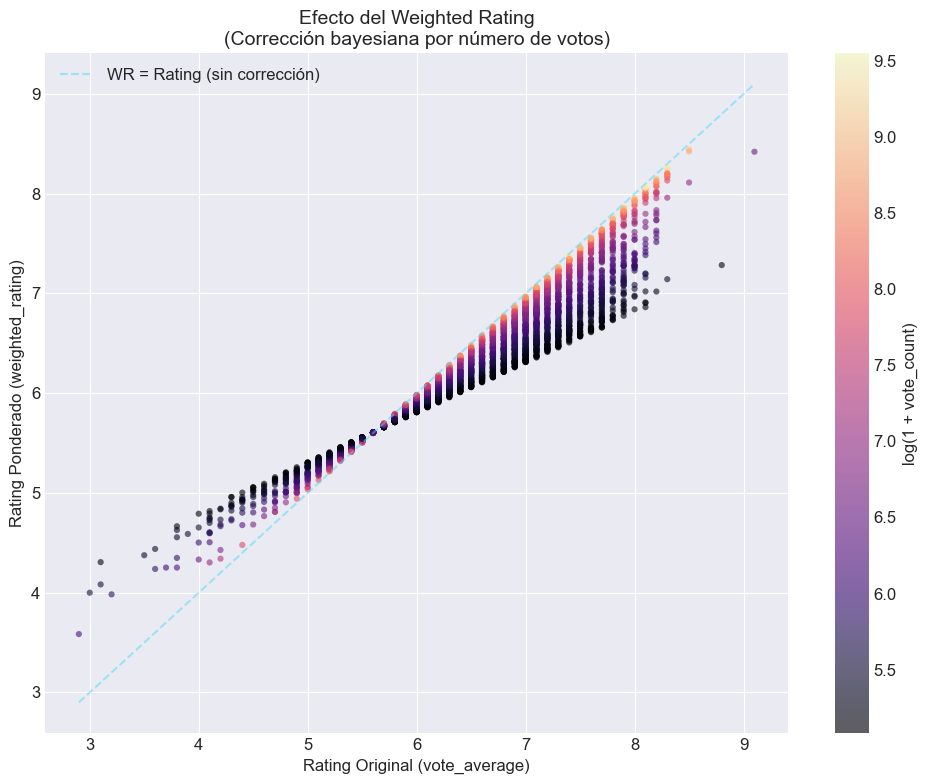


   💾 Guardado: output/01_efecto_weighted_rating.png
   📝 Nota: Los puntos debajo de la diagonal son películas cuyo
      rating fue 'reducido' por tener relativamente pocos votos.


In [7]:
def visualize_weighted_rating_effect(df):
    """
    Muestra visualmente cómo la fórmula de WR corrige el sesgo
    de películas con pocos votos.
    """
    ensure_output_dir()
    C = df["vote_average"].mean()
    m = df["vote_count"].quantile(0.90)

    qualified_wr = df[df["vote_count"] >= m].copy()
    qualified_wr["weighted_rating"] = qualified_wr.apply(
        weighted_rating, axis=1, m=m, C=C
    )

    fig, ax = plt.subplots(figsize=(10, 8))
    scatter = ax.scatter(
        qualified_wr["vote_average"],
        qualified_wr["weighted_rating"],
        c=np.log1p(qualified_wr["vote_count"]),
        cmap="magma",
        alpha=0.6,
        s=20,
        edgecolors="none"
    )

    lim = [qualified_wr["vote_average"].min(), qualified_wr["vote_average"].max()]
    ax.plot(lim, lim, "--", color="#53d8fb", alpha=0.5, label="WR = Rating (sin corrección)")

    ax.set_title("Efecto del Weighted Rating\n(Corrección bayesiana por número de votos)")
    ax.set_xlabel("Rating Original (vote_average)")
    ax.set_ylabel("Rating Ponderado (weighted_rating)")
    plt.colorbar(scatter, label="log(1 + vote_count)")
    ax.legend()

    plt.tight_layout()
    path = f"{OUTPUT_DIR}/01_efecto_weighted_rating.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n   💾 Guardado: {path}")
    print("   📝 Nota: Los puntos debajo de la diagonal son películas cuyo")
    print("      rating fue 'reducido' por tener relativamente pocos votos.")

visualize_weighted_rating_effect(df)

In [8]:
print("\n" + "=" * 70)
print("✅ Módulo 01 completado exitosamente. Visualizaciones generadas en output/")
print("=" * 70)


✅ Módulo 01 completado exitosamente. Visualizaciones generadas en output/
